In [ ]:
!mkdir -p ~/work/semantic_segmentation/data
!wget https://s3.eu-central-1.amazonaws.com/avg-kitti/data_semantics.zip
!unzip data_semantics.zip -d ~/work/semantic_segmentation/data/

--2026-02-26 05:54:21--  https://s3.eu-central-1.amazonaws.com/avg-kitti/data_semantics.zip
Resolving s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)... 52.219.170.5, 3.5.135.43, 3.5.139.203, ...
Connecting to s3.eu-central-1.amazonaws.com (s3.eu-central-1.amazonaws.com)|52.219.170.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 327699796 (313M) [application/zip]
Saving to: ‘data_semantics.zip.2’

data_semantics.zip. 100%[===================>] 312.52M  18.0MB/s    in 19s     

2026-02-26 05:54:41 (16.6 MB/s) - ‘data_semantics.zip.2’ saved [327699796/327699796]

Archive:  data_semantics.zip
replace /home/jovyan/work/semantic_segmentation/data/testing/image_2/000000_10.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [1]:
!pip install albumentations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 93.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 583.0/583.0 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 112.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [albumentations]m [albumentations]eadless]


In [2]:
#필요한 라이브러리를 로드합니다.
import os
import math
import numpy as np
import torch
import torchvision.transforms as transforms

from PIL import Image
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.transform import resize
from glob import glob

import torch.nn as nn
import torch.optim as optim

print('=3')

=3


In [4]:
from albumentations import  HorizontalFlip, RandomSizedCrop, Compose, OneOf, Resize

def build_augmentation(is_train=True):
  if is_train:    # 훈련용 데이터일 경우
    return Compose([
                    HorizontalFlip(p=0.5),    # 50%의 확률로 좌우대칭
                    RandomSizedCrop(         # 50%의 확률로 RandomSizedCrop
                        min_max_height=(300, 370),
                        w2h_ratio=370/1242,
                        height=224,
                        width=224,
                        size=(224, 224),
                        p=0.5
                        ),
                    Resize(              # 입력이미지를 224X224로 resize
                        width=224,
                        height=224
                        )
                    ])
  return Compose([      # 테스트용 데이터일 경우에는 224X224로 resize만 수행합니다.
                Resize(
                    width=224,
                    height=224
                    )
                ])

/tmp/ipykernel_191/2497950994.py:7: UserWarning: Argument(s) 'height, width' are not valid for transform RandomSizedCrop
  RandomSizedCrop(         # 50%의 확률로 RandomSizedCrop


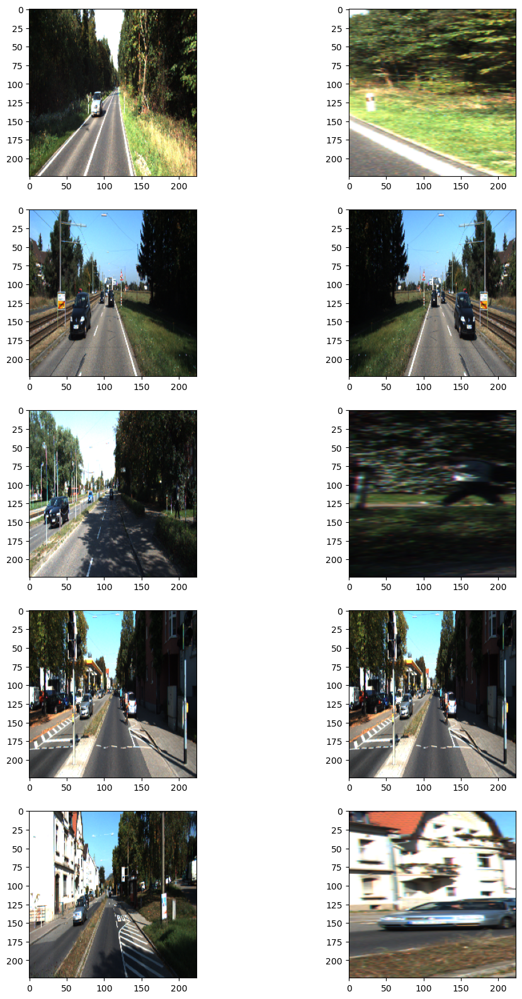

In [5]:
data_dir = os.path.join(os.getenv("HOME"), "work/semantic_segmentation/data/training")

augmentation_train = build_augmentation()
augmentation_test = build_augmentation(is_train=False)
input_images = glob(os.path.join(data_dir, "image_2", "*.png"))

# 훈련 데이터셋에서 5개만 가져와 augmentation을 적용해 봅시다.
plt.figure(figsize=(12, 20))
for i in range(5):
    image = imread(input_images[i])
    image_data = {"image":image}
    resized = augmentation_test(**image_data)
    processed = augmentation_train(**image_data)
    plt.subplot(5, 2, 2*i+1)
    plt.imshow(resized["image"])  # 왼쪽이 원본이미지
    plt.subplot(5, 2, 2*i+2)
    plt.imshow(processed["image"])  # 오른쪽이 augment된 이미지

plt.show()

In [6]:
from torch.utils.data import Dataset

class KittiDataset(Dataset):
    '''
    KittiDataset은 PyTorch의 Dataset을 상속받습니다.
    우리가 KittiDataset을 원하는 방식으로 preprocess하기 위해서 Dataset을 커스텀하여 사용합니다.
    '''
    def __init__(self,
                 dir_path,
                 img_size=(224, 224, 3),
                 output_size=(224, 224),
                 is_train=True,
                 augmentation=None):
        '''
        dir_path: dataset의 directory path입니다.
        img_size: preprocess에 사용할 입력이미지의 크기입니다.
        output_size: ground_truth를 만들어주기 위한 크기입니다.
        is_train: 이 Dataset이 학습용인지 테스트용인지 구분합니다.
        augmentation: 적용하길 원하는 augmentation 함수를 인자로 받습니다.
        '''
        self.dir_path = dir_path
        self.is_train = is_train
        self.augmentation = augmentation
        self.img_size = img_size
        self.output_size = output_size

        # load_dataset()을 통해 kitti dataset의 경로에서 라벨과 이미지를 확인합니다.
        self.data = self.load_dataset()

    def load_dataset(self):
        # kitti dataset에서 필요한 정보(이미지 경로 및 라벨)를 directory에서 확인하고 로드하는 함수입니다.
        input_images = sorted(glob(os.path.join(self.dir_path, "image_2", "*.png")))
        label_images = sorted(glob(os.path.join(self.dir_path, "semantic", "*.png")))

        assert len(input_images) == len(label_images)
        data = list(zip(input_images, label_images))

        if self.is_train:
            return data[:-30]
        return data[-30:]

    def __len__(self):
        # Dataset의 length로서 전체 dataset 크기를 반환합니다.
        return len(self.data)

    def __getitem__(self, index):
        # 입력과 출력을 만듭니다.
        # 입력은 resize 및 augmentation이 적용된 input image이고
        # 출력은 semantic label입니다.
        input_img_path, output_path = self.data[index]

        _input = imread(input_img_path)
        _output = imread(output_path)

        # 특정 라벨을 이진 마스크로 변환
        _output = (_output == 7).astype(np.uint8) * 1

        data = {
            "image": _input,
            "mask": _output,
        }

        if self.augmentation:
            augmented = self.augmentation(**data)
            _input = augmented["image"] / 255.0  # Normalize
            _output = augmented["mask"]

        # 📌 target 차원 확장 (H, W) → (1, H, W)
        _output = np.expand_dims(_output, axis=0)

        return (
            torch.tensor(_input, dtype=torch.float32).permute(2, 0, 1),  # (H, W, C) → (C, H, W)
            torch.tensor(_output, dtype=torch.float32)  # (1, H, W) 형식 유지
        )

    def shuffle_data(self):
        # 한 epoch가 끝나면 실행되는 함수입니다. 학습 중인 경우에 데이터를 random shuffle합니다.
        if self.is_train:
            np.random.shuffle(self.data)

In [10]:
from torch.utils.data import DataLoader

# Augmentation 설정
augmentation = build_augmentation()
test_preproc = build_augmentation(is_train=False)

train_dataset = KittiDataset(
    data_dir,
    augmentation=augmentation,
    is_train=True
)

test_dataset = KittiDataset(
    data_dir,
    augmentation=test_preproc,
    is_train=False
)

# DataLoader 설정
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

/tmp/ipykernel_191/2497950994.py:7: UserWarning: Argument(s) 'height, width' are not valid for transform RandomSizedCrop
  RandomSizedCrop(         # 50%의 확률로 RandomSizedCrop


In [11]:
import torch.nn.functional as F

class UNet(nn.Module):
    def __init__(self, input_channels=3, output_channels=1):
        super(UNet, self).__init__()

        # Contracting Path (Encoder)
        self.enc1 = self.double_conv(input_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = self.double_conv(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = self.double_conv(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = self.double_conv(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = self.double_conv(512, 1024)
        self.dropout = nn.Dropout(0.5)

        # Expanding Path (Decoder)
        self.up6 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec6 = self.double_conv(1024, 512)
        self.up7 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec7 = self.double_conv(512, 256)
        self.up8 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec8 = self.double_conv(256, 128)
        self.up9 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec9 = self.double_conv(128, 64)

        # Output layer
        self.final = nn.Conv2d(64, output_channels, kernel_size=1)

    def double_conv(self, in_channels, out_channels):
        """2개의 Conv Layer로 이루어진 블록"""
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        # Encoder
        c1 = self.enc1(x)
        p1 = self.pool1(c1)
        c2 = self.enc2(p1)
        p2 = self.pool2(c2)
        c3 = self.enc3(p2)
        p3 = self.pool3(c3)
        c4 = self.enc4(p3)
        p4 = self.pool4(c4)

        # Bottleneck
        c5 = self.bottleneck(p4)
        c5 = self.dropout(c5)

        # Decoder
        u6 = self.up6(c5)
        u6 = torch.cat([u6, c4], dim=1)
        c6 = self.dec6(u6)

        u7 = self.up7(c6)
        u7 = torch.cat([u7, c3], dim=1)
        c7 = self.dec7(u7)

        u8 = self.up8(c7)
        u8 = torch.cat([u8, c2], dim=1)
        c8 = self.dec8(u8)

        u9 = self.up9(c8)
        u9 = torch.cat([u9, c1], dim=1)
        c9 = self.dec9(u9)

        # Output
        output = torch.sigmoid(self.final(c9))
        return output

In [12]:
%%time

# 모델 저장 경로
model_path = "./work/semantic_segmentation/seg_model_unet.pth"

# 모델 생성
model = UNet(input_channels=3, output_channels=1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 손실 함수 및 옵티마이저 설정
criterion = torch.nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 데이터로더 준비
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

# 모델 학습
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets.float())  # 타겟을 float 타입으로 변환
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader)}")

# 모델 저장
torch.save(model.state_dict(), model_path)

Epoch 1/100, Loss: 0.6817597259174694
Epoch 2/100, Loss: 0.6384975747628645
Epoch 3/100, Loss: 0.565052021633495
Epoch 4/100, Loss: 0.5365622748028148
Epoch 5/100, Loss: 0.43536683917045593
Epoch 6/100, Loss: 0.405316025018692
Epoch 7/100, Loss: 0.3513290123506026
Epoch 8/100, Loss: 0.3370989832011136
Epoch 9/100, Loss: 0.3003947938030416
Epoch 10/100, Loss: 0.2882508188486099
Epoch 11/100, Loss: 0.27203667163848877
Epoch 12/100, Loss: 0.23993874408982016
Epoch 13/100, Loss: 0.24705130674622275
Epoch 14/100, Loss: 0.228666445071047
Epoch 15/100, Loss: 0.21370960636572403
Epoch 16/100, Loss: 0.22643416036259045
Epoch 17/100, Loss: 0.21867365322329782
Epoch 18/100, Loss: 0.22180454568429428
Epoch 19/100, Loss: 0.20171191882003436
Epoch 20/100, Loss: 0.19974481111223047
Epoch 21/100, Loss: 0.21043809029189023
Epoch 22/100, Loss: 0.18609627878124063
Epoch 23/100, Loss: 0.1754294688051397
Epoch 24/100, Loss: 0.170138764787804
Epoch 25/100, Loss: 0.18010849302465265
Epoch 26/100, Loss: 0.179

RuntimeError: Parent directory ./work/semantic_segmentation does not exist.

In [24]:
import os
import torch

# 1. 올바른 경로 설정 (홈 디렉토리 기준)
model_path = os.path.expanduser("~/work/semantic_segmentation/seg_model_unet.pth")

# 2. 저장할 폴더 생성 (이미 있으면 무시됨)
os.makedirs(os.path.dirname(model_path), exist_ok=True)

# 3. 메모리에 살아있는 'model'을 그대로 저장!
torch.save(model.state_dict(), model_path)

print(f"모델이 무사히 저장되었습니다: {model_path}")

모델이 무사히 저장되었습니다: /home/jovyan/work/semantic_segmentation/seg_model_unet.pth


In [25]:
model = UNet(input_channels=3, output_channels=1)
model.load_state_dict(torch.load(model_path, map_location=torch.device('cpu')))
model.eval()  # 평가 모드로 전환

UNet(
  (enc1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc4): Sequential(
    (0): Con

In [34]:
import cv2  # 테두리 추출을 위해 최상단에 추가되어야 합니다.

def get_output(model, preproc, image_path, output_path):
    # --- [기존 코드 유지] ---
    origin_img = imread(image_path)
    data = {"image": origin_img}

    processed = preproc(**data)
    input_tensor = torch.tensor(processed["image"] / 255.0, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)

    # 1. 🚨 바이너리 마스크 생성 (Threshold 적용)
    # output[0]은 (1, 224, 224) 형태이므로 squeeze()로 (224, 224)로 만듭니다.
    mask = (output[0].squeeze().numpy() > 0.5).astype(np.uint8)

    # 2. 🚨 테두리 추출을 위해 마스크를 원본 이미지 크기로 리사이즈
    mask_resized = cv2.resize(mask, (origin_img.shape[1], origin_img.shape[0]))

    # 3. 🚨 OpenCV로 도로의 경계선(Contour) 찾기
    contours, _ = cv2.findContours(mask_resized, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 4. 🚨 원본 이미지 복사본 위에 빨간색 테두리 그리기
    res_img = origin_img.copy()
    # cv2.drawContours(이미지, 테두리정보, 전체(-1), 색상(R,G,B), 두께)
    cv2.drawContours(res_img, contours, -1, (255, 0, 0), 3) 

    # --- [기존 저장 및 시각화 구조 유지] ---
    blended = Image.fromarray(res_img)
    blended.save(output_path)

    plt.imshow(res_img)
    plt.axis('off')
    plt.show()

    return blended

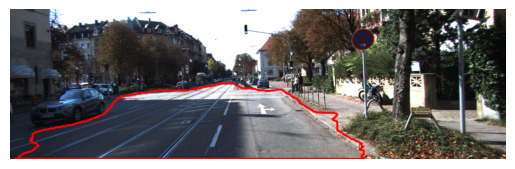

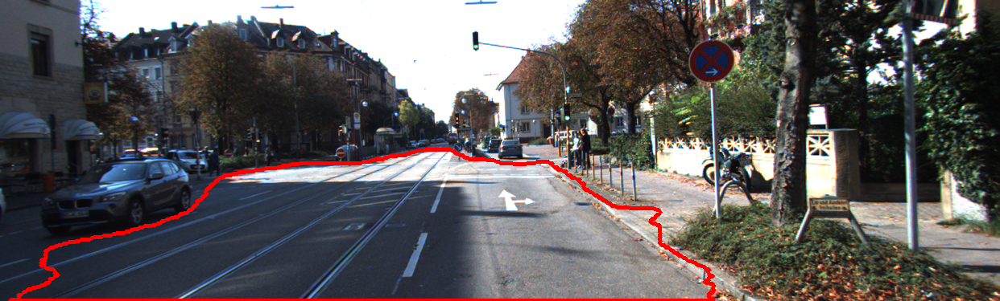

In [35]:
dir_path = os.path.expanduser('~/work/semantic_segmentation/data/training')
# 완성한 뒤에는 시각화한 결과를 눈으로 확인해봅시다!
i = 1    # i값을 바꾸면 테스트용 파일이 달라집니다.
get_output(
     model,
     test_preproc,
     image_path=dir_path + f'/image_2/00{str(i).zfill(4)}_10.png',
     output_path=dir_path + f'/result_{str(i).zfill(3)}.png'
 )

In [36]:
def calculate_iou_score(target, prediction):
    if target.shape != prediction.shape:
        prediction = resize(prediction, target.shape, mode='constant', preserve_range=True).astype(np.uint8)

    intersection = np.logical_and(target, prediction).sum() # intersection을 구하는 코드를 작성해주세요.
    union = np.logical_or(target, prediction).sum() # intersection을 구하는 코드를 작성해주세요.
    iou_score = intersection / (union + 1e-7)  # iou 스코어를 구하되 결과값을 float로 만들어주세요!
    print(f"IoU : {iou_score:.6f}")
    return iou_score

In [39]:
def get_output(model, preproc, image_path, output_path, label_path=None):
    origin_img = imread(image_path)
    data = {"image": origin_img}
    processed = preproc(**data)
    input_tensor = torch.tensor(processed["image"] / 255.0, dtype=torch.float32)
    input_tensor = input_tensor.permute(2, 0, 1).unsqueeze(0)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)

    prediction = (output[0].squeeze().numpy() > 0.5).astype(np.uint8) * 255
    prediction = Image.fromarray(prediction).convert('L')

    background = Image.fromarray(origin_img).convert('RGBA')
    prediction_resized = prediction.resize((origin_img.shape[1], origin_img.shape[0])).convert('RGBA')
    blended = Image.blend(background, prediction_resized, alpha=0.5)

    # 🚨 [수정된 부분] 빨간색 테두리 추가 로직
    # 1. 시각화용 이미지를 numpy 배열로 변환 (RGB)
    img_np = np.array(blended.convert("RGB"))

    # 2. 테두리 추출을 위한 마스크 준비 (이미 prediction 변수가 마스크 역할을 함)
    mask_np = np.array(prediction.resize((origin_img.shape[1], origin_img.shape[0])))
    
    # 3. OpenCV로 테두리(Contour) 찾기
    contours, _ = cv2.findContours(mask_np, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    # 4. 발견된 테두리를 빨간색(255, 0, 0), 두께 3으로 그리기
    cv2.drawContours(img_np, contours, -1, (255, 0, 0), 3)

    # 5. 테두리가 그려진 이미지를 다시 PIL로 변환하여 저장
    final_blended = Image.fromarray(img_np)
    final_blended.save(output_path)

    # 시각화
    plt.imshow(img_np)
    plt.axis('off')
    plt.show()

    target = None
    if label_path:
        label_img = imread(label_path)
        label_data = {"image": label_img}
        label_processed = preproc(**label_data)["image"]
        target = (label_processed == 7).astype(np.uint8) * 1

    # 기존 리턴 구조 유지 (prediction은 원본 크기가 아닌 모델 출력 크기 기준이므로 주의)
    return final_blended, np.array(prediction), target

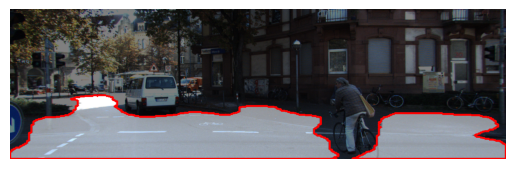

IoU : 0.704701


np.float64(0.7047012061355215)

In [41]:
# 완성한 뒤에는 시각화한 결과를 눈으로 확인해봅시다!
i = 2    # i값을 바꾸면 테스트용 파일이 달라집니다.
output, prediction, target = get_output(
     model,
     test_preproc,
     image_path=dir_path + f'/image_2/00{str(i).zfill(4)}_10.png',
     output_path=dir_path + f'/result_{str(i).zfill(3)}.png',
     label_path=dir_path + f'/semantic/00{str(i).zfill(4)}_10.png'
 )

calculate_iou_score(target, prediction)

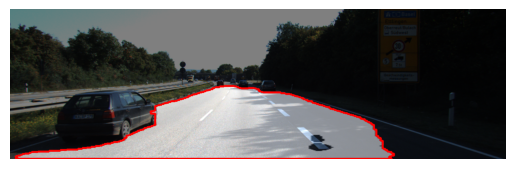

IoU : 0.765638


np.float64(0.7656380952322618)

In [42]:
# 완성한 뒤에는 시각화한 결과를 눈으로 확인해봅시다!
i = 100    # i값을 바꾸면 테스트용 파일이 달라집니다.
output, prediction, target = get_output(
     model,
     test_preproc,
     image_path=dir_path + f'/image_2/00{str(i).zfill(4)}_10.png',
     output_path=dir_path + f'/result_{str(i).zfill(3)}.png',
     label_path=dir_path + f'/semantic/00{str(i).zfill(4)}_10.png'
 )

calculate_iou_score(target, prediction)

## U-net++ 구현하기

In [44]:
# 라이브러리 버전 체크
import torch
import numpy as np
import PIL
import skimage
import albumentations

print(torch.__version__)
print(np.__version__)
print(PIL.__version__)
print(skimage.__version__)
print(albumentations.__version__)

2.7.1+cu118
2.2.6
11.2.1
0.25.2
2.0.8


# Step1. KITTI 데이터셋 수집과 구축
- 이전 노드에서 Unet에서 진행한 내역과 같으므로 똑같이 실행해도 무방함

# Step2. U-net++모델의 구현

In [45]:
class UNetPlusPlus(nn.Module):
    # 🚨 [차이점 1] Deep Supervision 옵션 추가
    # 중간 노드들(x0_1, x0_2, x0_3)의 결과물도 출력할지 결정하는 인자입니다.
    def __init__(self, input_channels=3, output_channels=1, deep_supervision=False):
        super(UNetPlusPlus, self).__init__()
        self.deep_supervision = deep_supervision
        
        # 각 층(Level)의 채널 수를 리스트로 관리하면 코드가 훨씬 깔끔해집니다.
        nb_filter = [64, 128, 256, 512, 1024]

        self.pool = nn.MaxPool2d(2, 2)
        
        # 🚨 [차이점 2] Upsample 블록의 간소화
        # 기존 U-Net은 ConvTranspose2d를 썼지만, U-Net++에서는 노드가 너무 많아 
        # 가이드라인의 조언대로 'Upsample2D_block' 역할을 하는 nn.Upsample을 주로 사용합니다.
        self.up = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # -------------------------------------------------------------------------
        # 1. Contracting Path (Encoder) - 기존 U-Net과 완벽히 동일합니다.
        # -------------------------------------------------------------------------
        self.conv0_0 = self.double_conv(input_channels, nb_filter[0])
        self.conv1_0 = self.double_conv(nb_filter[0], nb_filter[1])
        self.conv2_0 = self.double_conv(nb_filter[1], nb_filter[2])
        self.conv3_0 = self.double_conv(nb_filter[2], nb_filter[3])
        self.conv4_0 = self.double_conv(nb_filter[3], nb_filter[4])

        # -------------------------------------------------------------------------
        # 🚨 [차이점 3] Nested Skip Connections (중간 노드들)
        # 수식 (1)에 따라, 이전 노드들의 채널 합과 아래층에서 올라온 채널 합을 계산하여 in_channels를 설정합니다.
        # -------------------------------------------------------------------------
        # Level 1 (j=1)
        self.conv0_1 = self.double_conv(nb_filter[0] + nb_filter[1], nb_filter[0])
        self.conv1_1 = self.double_conv(nb_filter[1] + nb_filter[2], nb_filter[1])
        self.conv2_1 = self.double_conv(nb_filter[2] + nb_filter[3], nb_filter[2])
        self.conv3_1 = self.double_conv(nb_filter[3] + nb_filter[4], nb_filter[3])

        # Level 2 (j=2)
        self.conv0_2 = self.double_conv(nb_filter[0]*2 + nb_filter[1], nb_filter[0])
        self.conv1_2 = self.double_conv(nb_filter[1]*2 + nb_filter[2], nb_filter[1])
        self.conv2_2 = self.double_conv(nb_filter[2]*2 + nb_filter[3], nb_filter[2])

        # Level 3 (j=3)
        self.conv0_3 = self.double_conv(nb_filter[0]*3 + nb_filter[1], nb_filter[0])
        self.conv1_3 = self.double_conv(nb_filter[1]*3 + nb_filter[2], nb_filter[1])

        # Level 4 (j=4) - 최종 디코더 노드
        self.conv0_4 = self.double_conv(nb_filter[0]*4 + nb_filter[1], nb_filter[0])

        # -------------------------------------------------------------------------
        # 🚨 [차이점 4] Deep Supervision을 위한 다중 출력층
        # -------------------------------------------------------------------------
        self.final1 = nn.Conv2d(nb_filter[0], output_channels, kernel_size=1)
        self.final2 = nn.Conv2d(nb_filter[0], output_channels, kernel_size=1)
        self.final3 = nn.Conv2d(nb_filter[0], output_channels, kernel_size=1)
        self.final4 = nn.Conv2d(nb_filter[0], output_channels, kernel_size=1)

    def double_conv(self, in_channels, out_channels):
        # 💡 [팁] U-Net++는 학습이 까다로워 BatchNorm2d를 추가하는 것이 성능 향상에 아주 좋습니다.
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels), 
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        # Encoder (Downsampling)
        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x4_0 = self.conv4_0(self.pool(x3_0))

        # 🚨 [차이점 5] Dense Concatenation (밀집 결합)
        # 수식에 따라 같은 행에 있는 모든 이전 노드와 아래층 노드를 torch.cat으로 묶습니다.
        
        # j=1
        x0_1 = self.conv0_1(torch.cat([x0_0, self.up(x1_0)], dim=1))
        x1_1 = self.conv1_1(torch.cat([x1_0, self.up(x2_0)], dim=1))
        x2_1 = self.conv2_1(torch.cat([x2_0, self.up(x3_0)], dim=1))
        x3_1 = self.conv3_1(torch.cat([x3_0, self.up(x4_0)], dim=1))

        # j=2
        x0_2 = self.conv0_2(torch.cat([x0_0, x0_1, self.up(x1_1)], dim=1))
        x1_2 = self.conv1_2(torch.cat([x1_0, x1_1, self.up(x2_1)], dim=1))
        x2_2 = self.conv2_2(torch.cat([x2_0, x2_1, self.up(x3_1)], dim=1))

        # j=3
        x0_3 = self.conv0_3(torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], dim=1))
        x1_3 = self.conv1_3(torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], dim=1))

        # j=4
        x0_4 = self.conv0_4(torch.cat([x0_0, x0_1, x0_2, x0_3, self.up(x1_3)], dim=1))

        # 🚨 [차이점 6] 출력 방식 결정
        if self.deep_supervision:
            # 학습 시에는 각 단계의 결과를 모두 반환하여 Loss를 각각 구합니다.
            output1 = torch.sigmoid(self.final1(x0_1))
            output2 = torch.sigmoid(self.final2(x0_2))
            output3 = torch.sigmoid(self.final3(x0_3))
            output4 = torch.sigmoid(self.final4(x0_4))
            return [output1, output2, output3, output4]
        else:
            # 추론(Inference) 시에는 가장 마지막에 결합된 결과 하나만 사용합니다.
            output4 = torch.sigmoid(self.final4(x0_4))
            return output4

In [46]:
%%time
import torch.nn.functional as F

# 🚨 [수정된 부분 1] 손실 함수 정의 (BCE + Dice Coefficient)
# 가이드라인 수식 (2)를 참고하여 두 가지 Loss를 결합합니다.
def dice_loss(pred, target, smooth=1e-7):
    pred = pred.contiguous()
    target = target.contiguous()
    intersection = (pred * target).sum(dim=2).sum(dim=2)
    dice = (2. * intersection + smooth) / (pred.sum(dim=2).sum(dim=2) + target.sum(dim=2).sum(dim=2) + smooth)
    return 1 - dice.mean() # 1에서 빼주어 Loss 형태로 만듭니다.

def bce_dice_loss(pred, target):
    bce = F.binary_cross_entropy(pred, target)
    dice = dice_loss(pred, target)
    return bce + dice # 논문에 따라 두 Loss를 더해줍니다.

# 모델 저장 경로 변경
model_path = "./work/semantic_segmentation/seg_model_unetplusplus.pth"

# 🚨 [수정된 부분 2] U-Net++ 모델 생성 (Deep Supervision 활성화)
model = UNetPlusPlus(input_channels=3, output_channels=1, deep_supervision=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# 옵티마이저 설정
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# 🚨 [수정된 부분 3] 배치 사이즈 하향 조정
# U-Net++는 메모리 점유율이 높으므로 OOM 방지를 위해 배치 사이즈를 줄입니다.
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

# 모델 학습
num_epochs = 100
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device).float()

        optimizer.zero_grad()
        
        # 모델 추론
        outputs = model(inputs)
        
        # 🚨 [수정된 부분 4] Deep Supervision을 위한 Loss 계산
        loss = 0
        if isinstance(outputs, list):
            # 4개의 시맨틱 레벨에서 나온 모든 출력에 대해 Loss를 구하고 합산합니다.
            for out in outputs:
                loss += bce_dice_loss(out, targets)
            loss /= len(outputs) # 4개로 나누어 평균을 냅니다.
        else:
            loss = bce_dice_loss(outputs, targets)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.4f}")

# 모델 저장
torch.save(model.state_dict(), model_path)
print("U-Net++ 모델 학습 및 저장 완료!")

Epoch 1/100, Loss: 1.0704
Epoch 2/100, Loss: 0.9185
Epoch 3/100, Loss: 0.8299
Epoch 4/100, Loss: 0.8050
Epoch 5/100, Loss: 0.7983
Epoch 6/100, Loss: 0.7996
Epoch 7/100, Loss: 0.7222
Epoch 8/100, Loss: 0.7146
Epoch 9/100, Loss: 0.6939
Epoch 10/100, Loss: 0.7060
Epoch 11/100, Loss: 0.7307
Epoch 12/100, Loss: 0.6861
Epoch 13/100, Loss: 0.6760
Epoch 14/100, Loss: 0.6837
Epoch 15/100, Loss: 0.6296
Epoch 16/100, Loss: 0.6539
Epoch 17/100, Loss: 0.6562
Epoch 18/100, Loss: 0.6224
Epoch 19/100, Loss: 0.6052
Epoch 20/100, Loss: 0.5780
Epoch 21/100, Loss: 0.5789
Epoch 22/100, Loss: 0.5757
Epoch 23/100, Loss: 0.5912
Epoch 24/100, Loss: 0.5337
Epoch 25/100, Loss: 0.6104
Epoch 26/100, Loss: 0.5336
Epoch 27/100, Loss: 0.5638
Epoch 28/100, Loss: 0.5346
Epoch 29/100, Loss: 0.5622
Epoch 30/100, Loss: 0.5033
Epoch 31/100, Loss: 0.5196
Epoch 32/100, Loss: 0.5369
Epoch 33/100, Loss: 0.5170
Epoch 34/100, Loss: 0.4890
Epoch 35/100, Loss: 0.4852
Epoch 36/100, Loss: 0.4831
Epoch 37/100, Loss: 0.5069
Epoch 38/1

RuntimeError: Parent directory ./work/semantic_segmentation does not exist.

In [47]:
# 1. 안전한 절대 경로로 다시 설정 (이전 U-Net 저장 때 썼던 확실한 방식)
model_path = os.path.expanduser("~/work/semantic_segmentation/seg_model_unetplusplus.pth")

# 2. 해당 경로에 폴더가 없다면 생성 (exist_ok=True 덕분에 에러 안 남)
os.makedirs(os.path.dirname(model_path), exist_ok=True)

# 3. 메모리에 살아있는 U-Net++ 모델의 가중치를 저장!
torch.save(model.state_dict(), model_path)

print(f"U-Net++ 모델이 안전하게 구출되어 저장되었습니다: {model_path}")

U-Net++ 모델이 안전하게 구출되어 저장되었습니다: /home/jovyan/work/semantic_segmentation/seg_model_unetplusplus.pth


In [48]:
# 1. U-Net++ 모델 생성 (구조 확인 및 평가용이므로 deep_supervision은 False)
model_plus = UNetPlusPlus(input_channels=3, output_channels=1, deep_supervision=False)

# 2. 저장해둔 U-Net++ 가중치 불러오기 (cpu 환경 기준)
# 주의: 아까 에러를 피해서 저장했던 그 경로를 정확히 넣어주세요!
model_plus_path = os.path.expanduser("~/work/semantic_segmentation/seg_model_unetplusplus.pth")
model_plus.load_state_dict(torch.load(model_plus_path, map_location=torch.device('cpu')))

# 3. 평가 모드로 전환
model_plus.eval()

# 4. 🚨 U-Net++ 모델 구조가 어떻게 되어있는지 직접 눈으로 확인!
print(model_plus)

UNetPlusPlus(
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (up): Upsample(scale_factor=2.0, mode='bilinear')
  (conv0_0): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv1_0): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
  )
  (conv2_0): Sequen

In [49]:
def get_output_plus(model, preproc, image_path, output_path):
    """
    U-Net++ 모델의 결과를 시각화합니다.
    최대한 기존 코드를 유지하되, U-Net++ 모델을 인자로 받습니다.
    """
    # 1. 원본 이미지 로드 및 전처리 (기존 유지)
    origin_img = imread(image_path)
    data = {"image": origin_img}
    processed = preproc(**data)
    input_tensor = torch.tensor(processed["image"] / 255.0, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)

    # 2. 모델 추론 (Inference)
    # 🚨 주의: U-Net++ 모델의 deep_supervision은 False여야 단일 출력이 나옵니다.
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)

    # 3. 🚨 바이너리 마스크 생성 (Threshold 적용)
    # U-Net++의 최종 출력(x0_4)에서 마스크를 생성합니다.
    mask = (output[0].squeeze().cpu().numpy() > 0.5).astype(np.uint8)

    # 4. 테두리 추출을 위해 마스크를 원본 이미지 크기로 리사이즈 (기존 유지)
    mask_resized = cv2.resize(mask, (origin_img.shape[1], origin_img.shape[0]))

    # 5. OpenCV로 도로의 경계선(Contour) 찾기 (기존 유지)
    contours, _ = cv2.findContours(mask_resized, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # 6. 원본 이미지 위에 빨간색 테두리 그리기 (기존 유지)
    res_img = origin_img.copy()
    cv2.drawContours(res_img, contours, -1, (255, 0, 0), 3) 

    # 7. 저장 및 시각화 (기존 유지)
    blended = Image.fromarray(res_img)
    blended.save(output_path)

    plt.figure(figsize=(10, 5))
    plt.imshow(res_img)
    plt.title("U-Net++ Road Detection (Boundary)")
    plt.axis('off')
    plt.show()

    return blended

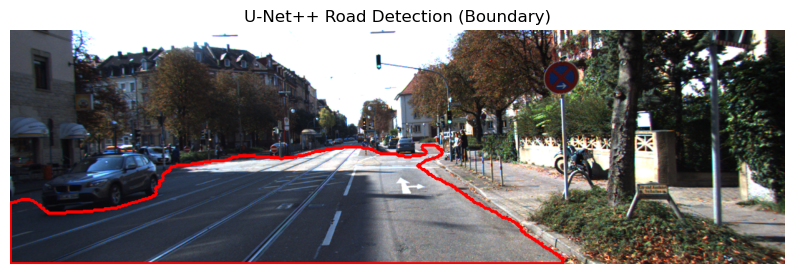

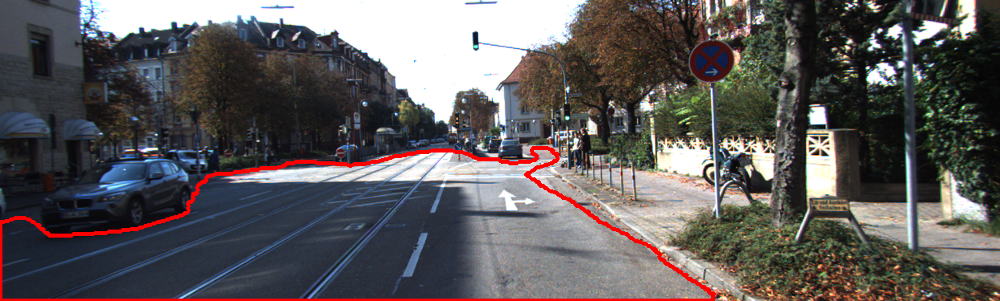

In [50]:
# 1. 데이터 경로 설정 (기존과 동일)
dir_path = os.path.expanduser('~/work/semantic_segmentation/data/training')

# 2. 테스트할 이미지 번호 설정
i = 1  # 이 값을 바꾸며 다양한 도로 상황에서 U-Net++의 성능을 확인해보세요.

# 3. U-Net++ 결과 확인 (get_output_plus 함수 사용)
# 🚨 주의: 이전에 불러온 U-Net++ 모델 변수명(예: model_plus)을 넣어주세요.
get_output_plus(
    model_plus,            # 학습된 U-Net++ 모델
    test_preproc,          # 테스트용 전처리 도구
    image_path=os.path.join(dir_path, f'image_2/00{str(i).zfill(4)}_10.png'),
    output_path=os.path.join(dir_path, f'result_plus_{str(i).zfill(3)}.png') # 구분을 위해 _plus 추가
)

In [54]:
def get_output(model, preproc, image_path, output_path, label_path=None):
    origin_img = imread(image_path)
    data = {"image": origin_img}
    processed = preproc(**data)
    input_tensor = torch.tensor(processed["image"] / 255.0, dtype=torch.float32)
    input_tensor = input_tensor.permute(2, 0, 1).unsqueeze(0)

    # 🚨 [수정된 부분 1] 모델이 위치한 디바이스(GPU)를 확인하고, 입력 텐서도 같은 곳으로 보냅니다.
    device = next(model.parameters()).device
    input_tensor = input_tensor.to(device)

    model.eval()
    with torch.no_grad():
        output = model(input_tensor)

    # 🚨 [수정된 부분 2] GPU에서 계산된 결과를 다시 CPU로 내려서 numpy 배열로 바꿉니다.
    prediction = (output[0].squeeze().cpu().numpy() > 0.5).astype(np.uint8) * 255
    prediction = Image.fromarray(prediction).convert('L')

    background = Image.fromarray(origin_img).convert('RGBA')
    prediction_resized = prediction.resize((origin_img.shape[1], origin_img.shape[0])).convert('RGBA')
    blended = Image.blend(background, prediction_resized, alpha=0.5)

    # --- 빨간색 테두리 추가 로직 ---
    img_np = np.array(blended.convert("RGB"))
    mask_np = np.array(prediction.resize((origin_img.shape[1], origin_img.shape[0])))
    
    contours, _ = cv2.findContours(mask_np, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img_np, contours, -1, (255, 0, 0), 3)

    final_blended = Image.fromarray(img_np)
    final_blended.save(output_path)

    # 시각화 (평가 코드에서 한 번에 보기 위해 여기서는 주석 처리하거나 빼두셔도 좋습니다)
    # plt.imshow(img_np)
    # plt.axis('off')
    # plt.show()

    target = None
    if label_path:
        label_img = imread(label_path)
        label_data = {"image": label_img}
        label_processed = preproc(**label_data)["image"]
        target = (label_processed == 7).astype(np.uint8) * 1

    return final_blended, np.array(prediction), target

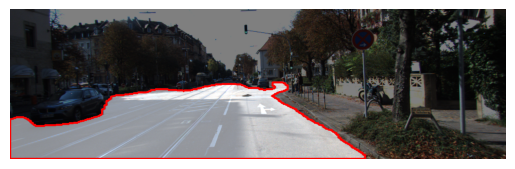

IoU : 0.936862


np.float64(0.9368624420329453)

In [56]:
# 완성한 뒤에는 시각화한 결과를 눈으로 확인해봅시다!
i = 1    # i값을 바꾸면 테스트용 파일이 달라집니다. 다양한 이미지로 테스트해보세요!

# 🚨 [수정 포인트 1] 방금 만든 get_output_plus 함수와 U-Net++ 모델(model_plus)을 사용합니다.
output_plus, prediction_plus, target_plus = get_output_plus(
     model_plus,  # 학습된 U-Net++ 모델 변수명
     test_preproc,
     image_path=dir_path + f'/image_2/00{str(i).zfill(4)}_10.png',
     output_path=dir_path + f'/result_plus_{str(i).zfill(3)}.png',  # 🚨 [수정 포인트 2] 파일명 구분
     label_path=dir_path + f'/semantic/00{str(i).zfill(4)}_10.png'
 )

# 🚨 [수정 포인트 3] U-Net++의 예측 결과로 IoU 스코어를 계산합니다.
calculate_iou_score(target_plus, prediction_plus)

🚀 테스트 이미지 번호: 2번 분석 시작

▶ U-Net 모델 평가 중...
IoU : 0.643844

▶ U-Net++ 모델 평가 중...


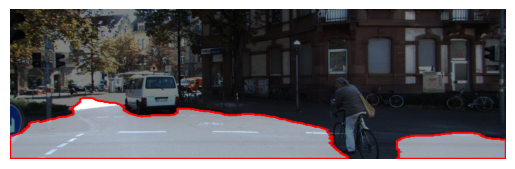

IoU : 0.808359


 📊 [정량적 평가] IoU 스코어 비교
 - U-Net   IoU : 0.643844
 - U-Net++ IoU : 0.808359
 👉 성능 차이  : +0.164515


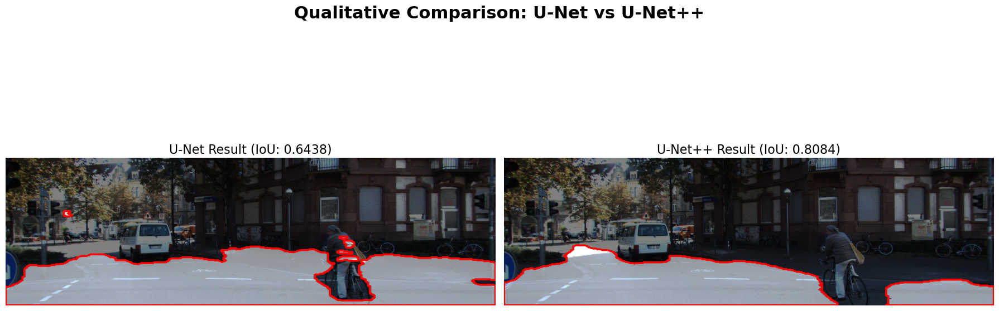

In [57]:
import matplotlib.pyplot as plt

# 1. 테스트할 이미지 번호 설정
i = 2  # 원하는 이미지 번호로 변경하며 테스트해보세요.
image_path = dir_path + f'/image_2/00{str(i).zfill(4)}_10.png'
label_path = dir_path + f'/semantic/00{str(i).zfill(4)}_10.png'

print("="*50)
print(f"🚀 테스트 이미지 번호: {i}번 분석 시작")
print("="*50)

# ---------------------------------------------------------
# [1] U-Net 모델 추론 및 IoU 계산
# ---------------------------------------------------------
print("\n▶ U-Net 모델 평가 중...")
output_unet, pred_unet, target_unet = get_output(
    model, 
    test_preproc, 
    image_path=image_path, 
    output_path=dir_path + f'/result_unet_{str(i).zfill(3)}.png', 
    label_path=label_path
)
# 함수 내부의 plt.show()가 한 번 실행됩니다.
iou_unet = calculate_iou_score(target_unet, pred_unet)


# ---------------------------------------------------------
# [2] U-Net++ 모델 추론 및 IoU 계산
# ---------------------------------------------------------
print("\n▶ U-Net++ 모델 평가 중...")
output_plus, pred_plus, target_plus = get_output_plus(
    model_plus, 
    test_preproc, 
    image_path=image_path, 
    output_path=dir_path + f'/result_plus_{str(i).zfill(3)}.png', 
    label_path=label_path
)
# 함수 내부의 plt.show()가 한 번 실행됩니다.
iou_plus = calculate_iou_score(target_plus, pred_plus)


# ---------------------------------------------------------
# [3] 📊 정량적 평가 (Quantitative Evaluation) 결과 요약
# ---------------------------------------------------------
print("\n\n" + "="*50)
print(" 📊 [정량적 평가] IoU 스코어 비교")
print("="*50)
print(f" - U-Net   IoU : {iou_unet:.6f}")
print(f" - U-Net++ IoU : {iou_plus:.6f}")
print(f" 👉 성능 차이  : {iou_plus - iou_unet:+.6f}")
print("="*50)


# ---------------------------------------------------------
# [4] 👁️ 정성적 평가 (Qualitative Evaluation) 나란히 보기
# ---------------------------------------------------------
# 두 모델의 결과를 한눈에 비교할 수 있도록 Subplot으로 나란히 시각화합니다.
plt.figure(figsize=(18, 8))

# 왼쪽: U-Net 결과
plt.subplot(1, 2, 1)
plt.title(f"U-Net Result (IoU: {iou_unet:.4f})", fontsize=16)
plt.imshow(output_unet)
plt.axis('off')

# 오른쪽: U-Net++ 결과
plt.subplot(1, 2, 2)
plt.title(f"U-Net++ Result (IoU: {iou_plus:.4f})", fontsize=16)
plt.imshow(output_plus)
plt.axis('off')

plt.suptitle("Qualitative Comparison: U-Net vs U-Net++", fontsize=22, fontweight='bold')
plt.tight_layout()
plt.show()

🚀 1번부터 10번 이미지까지 U-Net vs U-Net++ 연속 평가를 시작합니다!
IoU : 0.794225


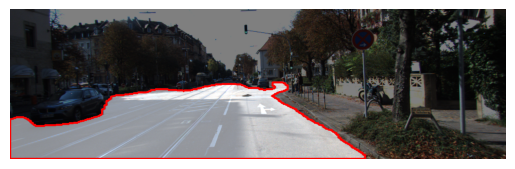

IoU : 0.936862
▶ [1번 이미지] U-Net: 0.7942 | U-Net++: 0.9369 | 향상도: +0.1426


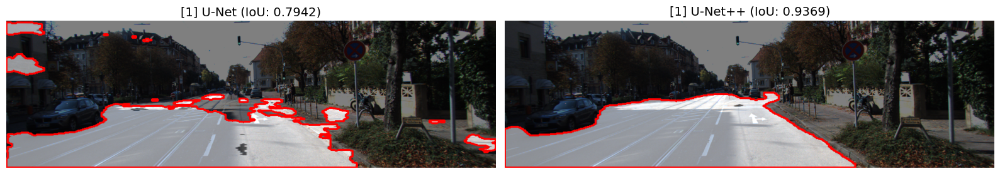

IoU : 0.643844


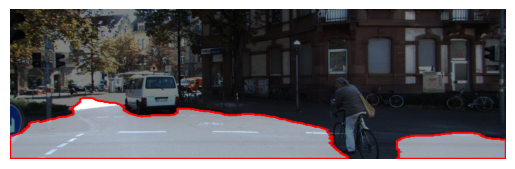

IoU : 0.808359
▶ [2번 이미지] U-Net: 0.6438 | U-Net++: 0.8084 | 향상도: +0.1645


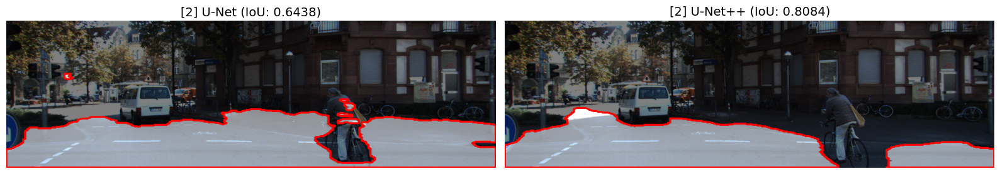

IoU : 0.281804


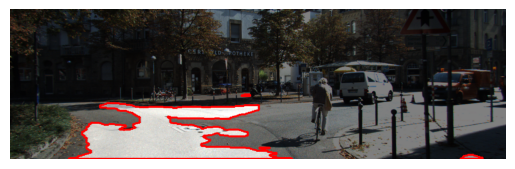

IoU : 0.399226
▶ [3번 이미지] U-Net: 0.2818 | U-Net++: 0.3992 | 향상도: +0.1174


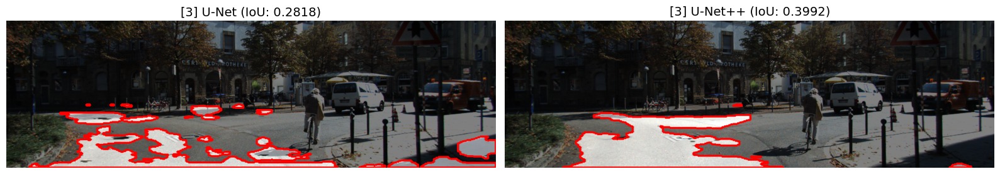

IoU : 0.721308


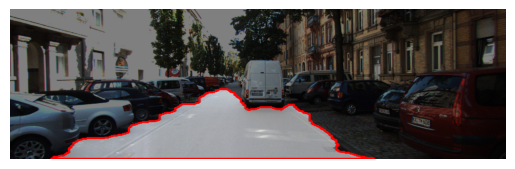

IoU : 0.791214
▶ [4번 이미지] U-Net: 0.7213 | U-Net++: 0.7912 | 향상도: +0.0699


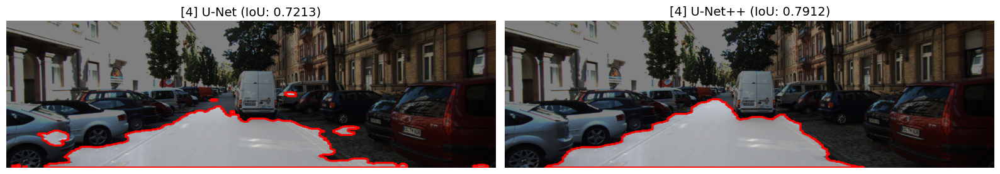

IoU : 0.699028


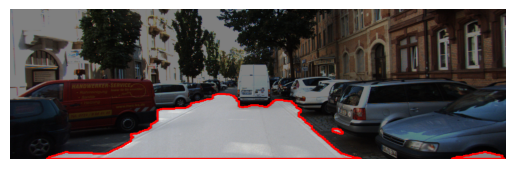

IoU : 0.847591
▶ [5번 이미지] U-Net: 0.6990 | U-Net++: 0.8476 | 향상도: +0.1486


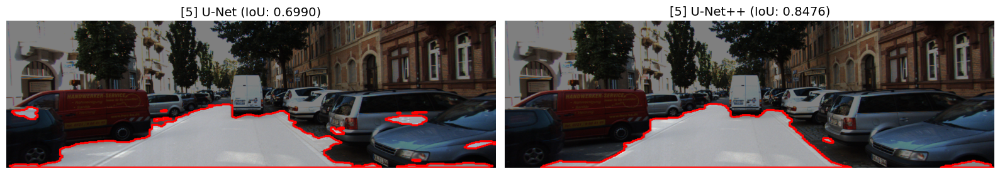

IoU : 0.697690


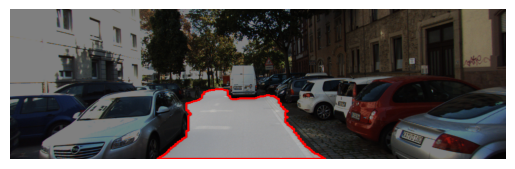

IoU : 0.906972
▶ [6번 이미지] U-Net: 0.6977 | U-Net++: 0.9070 | 향상도: +0.2093


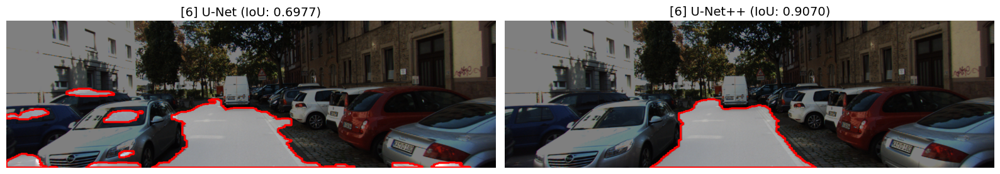

IoU : 0.721212


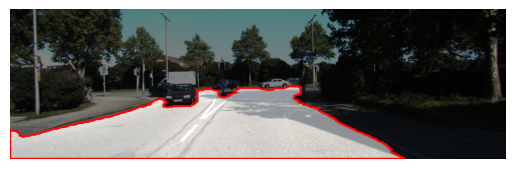

IoU : 0.939030
▶ [7번 이미지] U-Net: 0.7212 | U-Net++: 0.9390 | 향상도: +0.2178


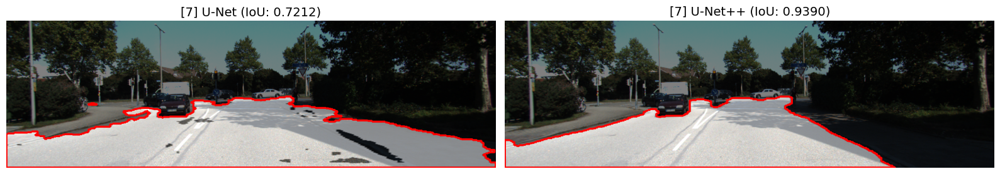

IoU : 0.674152


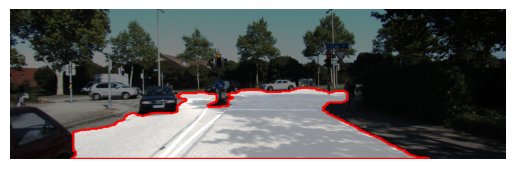

IoU : 0.901013
▶ [8번 이미지] U-Net: 0.6742 | U-Net++: 0.9010 | 향상도: +0.2269


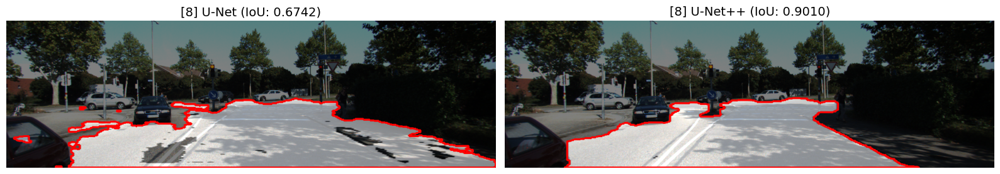

IoU : 0.730896


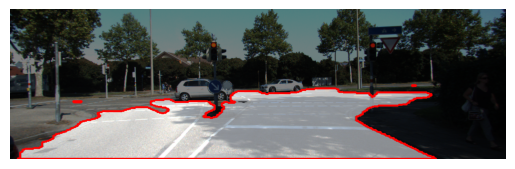

IoU : 0.854987
▶ [9번 이미지] U-Net: 0.7309 | U-Net++: 0.8550 | 향상도: +0.1241


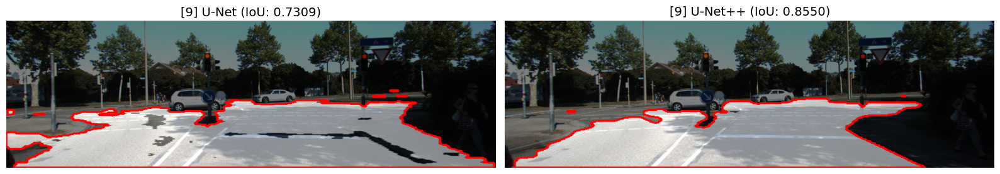

IoU : 0.687653


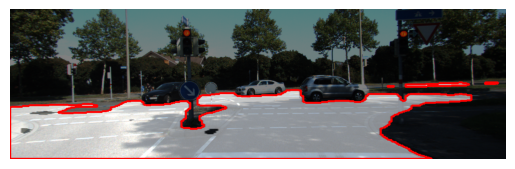

IoU : 0.839362
▶ [10번 이미지] U-Net: 0.6877 | U-Net++: 0.8394 | 향상도: +0.1517


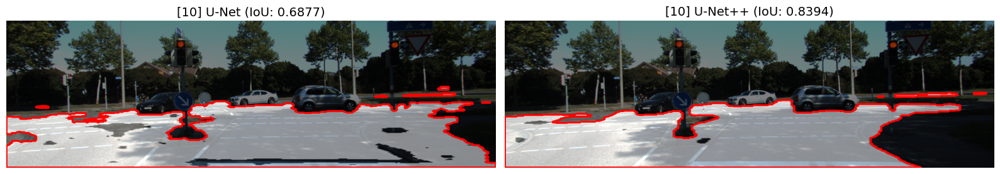


 🏆 [최종 결과 요약] 1~10번 테스트 이미지 평균 IoU 스코어
 - U-Net 평균 IoU   : 0.665181
 - U-Net++ 평균 IoU : 0.822462
 👉 평균 성능 향상  : +0.157281


In [59]:
import matplotlib.pyplot as plt
import numpy as np

# 평균 점수를 계산하기 위해 각 이미지의 IoU를 저장할 리스트
unet_ious = []
plus_ious = []

print("🚀 1번부터 10번 이미지까지 U-Net vs U-Net++ 연속 평가를 시작합니다!\n" + "="*60)

for i in range(1, 11):
    # 1. 파일 경로 설정 (1번~10번 순차적 접근)
    image_path = dir_path + f'/image_2/00{str(i).zfill(4)}_10.png'
    label_path = dir_path + f'/semantic/00{str(i).zfill(4)}_10.png'
    
    # 2. U-Net 추론 및 IoU 계산
    output_unet, pred_unet, target_unet = get_output(
        model, test_preproc, 
        image_path=image_path, 
        output_path=dir_path + f'/result_unet_{str(i).zfill(3)}.png', 
        label_path=label_path
    )
    iou_unet = calculate_iou_score(target_unet, pred_unet)
    unet_ious.append(iou_unet)
    
    # 3. U-Net++ 추론 및 IoU 계산
    output_plus, pred_plus, target_plus = get_output_plus(
        model_plus, test_preproc, 
        image_path=image_path, 
        output_path=dir_path + f'/result_plus_{str(i).zfill(3)}.png', 
        label_path=label_path
    )
    iou_plus = calculate_iou_score(target_plus, pred_plus)
    plus_ious.append(iou_plus)
    
    # 4. 결과 요약 출력 및 나란히 시각화
    print(f"▶ [{i}번 이미지] U-Net: {iou_unet:.4f} | U-Net++: {iou_plus:.4f} | 향상도: {iou_plus - iou_unet:+.4f}")
    
    plt.figure(figsize=(16, 6))
    
    # 왼쪽: U-Net 결과
    plt.subplot(1, 2, 1)
    plt.title(f"[{i}] U-Net (IoU: {iou_unet:.4f})", fontsize=14)
    plt.imshow(output_unet)
    plt.axis('off')
    
    # 오른쪽: U-Net++ 결과
    plt.subplot(1, 2, 2)
    plt.title(f"[{i}] U-Net++ (IoU: {iou_plus:.4f})", fontsize=14)
    plt.imshow(output_plus)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# 📊 [최종 결산] 1~10번 이미지 평균 IoU 비교
# ---------------------------------------------------------
print("\n" + "="*60)
print(" 🏆 [최종 결과 요약] 1~10번 테스트 이미지 평균 IoU 스코어")
print("="*60)
print(f" - U-Net 평균 IoU   : {np.mean(unet_ious):.6f}")
print(f" - U-Net++ 평균 IoU : {np.mean(plus_ious):.6f}")
print(f" 👉 평균 성능 향상  : {np.mean(plus_ious) - np.mean(unet_ious):+.6f}")
print("="*60)

## 💡 회고: 왜 U-Net++는 도로를 더 잘 찾았을까?
1. 의미론적 차이(Semantic Gap)의 극복
U-Net의 한계: 기존 U-Net은 얕은 층(Encoder)에서 추출한 '날것의 정보(직선, 픽셀의 밝기 등)'를 깊은 층(Decoder)의 '추상적 정보(이곳이 도로라는 의미)'에 곧바로 직접 연결합니다. 두 정보의 성격이 너무 달라서 모델이 이 둘을 부드럽게 융합하는 데 한계가 있음.

U-Net++의 돌파구: 이 문제를 해결하기 위해 엔코더와 디코더 사이에 여러 중간 노드(Nested Skip Connections)를 거미줄처럼 배치함. 얕은 특징이 여러 층의 합성곱(Convolution)을 점진적으로 거치며 깊은 특징으로 가공되기 때문에, 도로의 끝단이나 희미한 차선 같은 경계선 부근을 훨씬 정교하게 칠할 수 있었음.

2. DenseNet 아이디어를 통한 '정보 재사용' 극대화
U-Net++는 2018년 논문에서 제안된 모델로써 기존 구조에 DenseNet의 아이디어를 가미한 것이 핵심임.

우리가 코드를 짤 때 torch.cat([x0_0, x0_1, x0_2 ...]) 형태로 구현 -> 같은 층(Level)에 있는 과거의 노드들이 가진 특징 맵을 버리지 않고 다음 노드로 계속 누적해서 전달했습니다.

이렇게 정보를 밀집해서 엮어주면(Dense Connection), 신경망이 깊어져도 앞서 찾았던 중요한 도로의 특징을 잊어버리지 않아 정보 손실이 획기적으로 줄어듬.

3. Deep Supervision (다중 감독) 체계
일반적인 모델은 맨 마지막 출력층에서만 정답지(Label)와 비교해 채점을 받음.

하지만 U-Net++는 모델 학습 시 deep_supervision=True 옵션을 통해 4개의 중간 단계 출력 모두에서 손실(Loss)을 계산.

비유하자면, 기말고사 한 번만 보는 학생(U-Net)보다 수시로 쪽지 시험을 보며 피드백을 받은 학생(U-Net++)의 성적이 더 좋은 것과 같습니다. 모델의 앞단부터 뒷단까지 모든 노드가 '도로를 찾는 법'을 적극적으로 학습하게 됨.

4. 하이브리드 손실 함수 (BCE + Dice Loss)
가이드라인의 수식을 참고하여 구현한 새로운 손실 함수도 큰 역할을 했음.

단순히 픽셀 하나하나가 도로인지 묻는 BCE(Binary Cross Entropy)에, 예측 영역과 실제 정답 영역이 '얼마나 겹치는지'를 면적 단위로 평가하는 Dice Coefficient를 더함. 덕분에 좁고 길쭉한 형태를 띠는 도로의 형태적 특성을 모델이 훨씬 잘 이해하게 되었음.